In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ufc_betting.config import settings
from ufc_betting.BettingStrategy.MonteCarlo.mc_analysis import (
    summarize_simulations, analyze_bankroll_targets,
    geometric_growth_by_path, mean_event_exposure,
)
import importlib
from ufc_betting.BettingStrategy.MonteCarlo import mc_plots
importlib.reload(mc_plots)
from ufc_betting.BettingStrategy.MonteCarlo.mc_plots import (
    plot_bankroll_paths, plot_bankroll_targets, plot_terminal_return_distributions,
    plot_drawdown_count_histogram, plot_max_drawdown_histogram,
    plot_geometric_growth_distribution, plot_mean_bankroll_wagered,
)


In [7]:
# Load saved bankroll results; no simulation or model inference in this notebook.
RESULTS_PATH = settings.data_dir / "montecarlo_results" / "intermediate_results.pkl"
OUTPUT = RESULTS_PATH.parent / f"{RESULTS_PATH.stem}_metrics"
len_temp = 1  # Must match the value used in ufc_betting.BettingStrategy.MonteCarlo.run_simulation.
event_count = None  # Supply the original event count when len_temp > 1.
TARGETS = [5_000, 10_000, 25_000]

if not RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Run python -m ufc_betting.BettingStrategy.MonteCarlo.run_simulation separately to create {RESULTS_PATH}")
results = pd.read_pickle(RESULTS_PATH)  # Only load trusted pickle files.
if not isinstance(results, dict) or not results:
    raise ValueError("Expected a nonempty {label: simulation_result} dictionary")
# New archives record their actual event count and settlement batch size.
metadata = [r[3] for r in results.values() if len(r) > 3 and isinstance(r[3], dict)]
if metadata:
    saved_batches = {m["batch_size"] for m in metadata}
    saved_counts = {n for m in metadata for n in m["event_counts"]}
    if len(saved_batches) != 1 or len(saved_counts) != 1:
        raise ValueError("Plots require consistent batch sizes and event counts")
    len_temp = saved_batches.pop()
    event_count = saved_counts.pop()
target_paths = {label: np.asarray(result[2], dtype=float) for label, result in results.items()}
settlement_counts = {balances.shape[1] - 1 for balances in target_paths.values()}
if len(settlement_counts) != 1:
    raise ValueError("Combined event-target plots require equal path lengths across result groups")
if event_count is None:
    if len_temp != 1:
        raise ValueError("Set event_count for batched results; the final batch may be partial")
    event_count = settlement_counts.pop()
mc_summary, path_statistics = summarize_simulations(
    results, return_path_statistics=True, batch_size=len_temp, event_count=event_count,
)
print(f"Loaded {RESULTS_PATH}: {sum(len(p) for p in target_paths.values()):,} paths")


Loaded C:\Users\jcmar\my_files\SportsBetting\Data\montecarlo_results\intermediate_results.pkl: 5,000 paths


In [8]:
OUTPUT.mkdir(parents=True, exist_ok=True)
display(mc_summary.set_index("Prices").T.round(3))
print("Sharpe: mean of path-average event returns / sample SD of those path averages; unannualized.")
print("No-bet and post-ruin events contribute zero to each path average.")
print(f"Ulcer index and time underwater use recorded settlements (up to {len_temp} events each).")
display(path_statistics.round(3))
path_statistics.to_csv(OUTPUT / "path_statistics.csv", index=False)
mc_summary.to_csv(OUTPUT / "summary.csv", index=False)

# Record analysis settings; the saved dictionary does not contain simulation settings.
analysis_settings = dict(
    results_file=str(RESULTS_PATH),
    len_temp=len_temp, event_count=event_count,
    targets=TARGETS,
    bankroll_scale="log when positive, otherwise symlog", return_scale="symlog",
    ulcer_method="RMS percentage drawdown across post-settlement balances",
    underwater_method="count and percentage of settlements below running peak",
    sharpe_method="mean(path-average event returns) / sample SD(path-average event returns); unannualized; no-bet and post-ruin events contribute zero",
)
(OUTPUT / "analysis_settings.json").write_text(json.dumps(analysis_settings, indent=2), encoding="utf-8")


Prices,intermediate
Simulations,5000.000
Mean ending bankroll,81903.882
P05 ending bankroll,1905.022
P25 ending bankroll,9128.137
Median ending bankroll,26891.785
P75 ending bankroll,77785.044
Mean total return (%),16280.776
Median total return (%),5278.357
SD total return (%),42553.563
Profitable paths (%),99.060


Sharpe: mean of path-average event returns / sample SD of those path averages; unannualized.
No-bet and post-ruin events contribute zero to each path average.
Ulcer index and time underwater use recorded settlements (up to 1 events each).


,Prices,Simulation,Starting bankroll,Ending bankroll,Total profit,Total return (%),Max drawdown (%),Drawdown episodes >= 50%,Longest drawdown (settlements),Average event return (%),Ulcer index (%),Time underwater (settlements),Time underwater (%),Ruined
0,intermediate,1,500.0,945.244,445.244,89.049,75.924,2,36,2.821,45.294,65,90.278,False
1,intermediate,2,500.0,1713.029,1213.029,242.606,75.209,2,23,3.374,40.407,59,81.944,False
2,intermediate,3,500.0,4023.813,3523.813,704.763,67.550,3,20,4.910,29.710,55,76.389,False
3,intermediate,4,500.0,561611.587,561111.587,112222.317,46.074,0,11,11.779,14.916,28,38.889,False
4,intermediate,5,500.0,11994.845,11494.845,2298.969,69.972,1,24,6.408,32.776,48,66.667,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,intermediate,4996,500.0,46833.754,46333.754,9266.751,39.931,0,18,7.889,14.975,40,55.556,False
4996,intermediate,4997,500.0,92711.176,92211.176,18442.235,35.520,0,13,9.134,12.147,36,50.000,False
4997,intermediate,4998,500.0,147636.697,147136.697,29427.339,49.563,0,10,10.184,16.901,32,44.444,False
4998,intermediate,4999,500.0,16515.129,16015.129,3203.026,46.174,0,21,6.439,18.254,44,61.111,False


605

### Geometric growth and average event exposure
Growth is `(final / initial) ** (1 / event_count) - 1`, per scheduled event, for each path. For each path, average the total bankroll percentage wagered (singles plus parlays) across its events. The histogram and KDE show the distribution of these path averages: one observation per path. No-bet and post-ruin paths contribute zero exposure. Batched exposure is relative to the bankroll available at batch start.


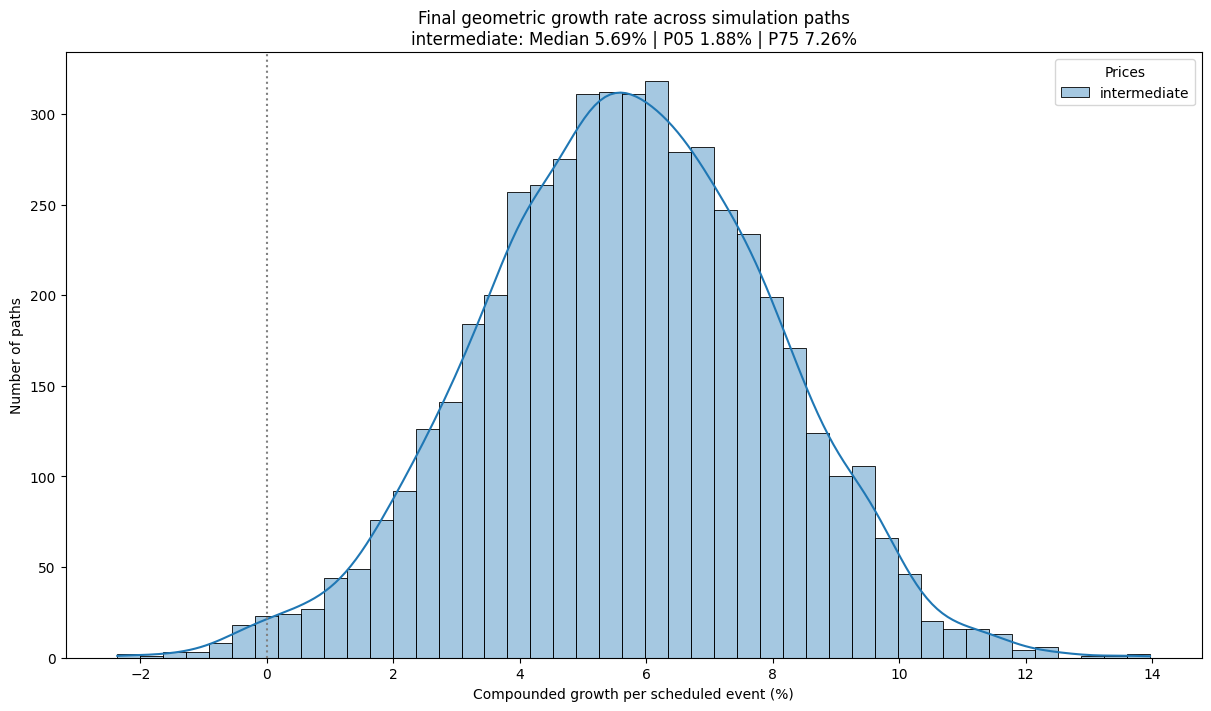

,count,mean,std,min,25%,50%,75%,max
Prices,,,,,,,,
intermediate,4999.0,5.671179,2.293019,-2.364877,4.118109,5.691884,7.261619,13.968958


Negative final bankroll paths (undefined geometric growth, excluded): {'intermediate': 1}
Zero final bankroll is included at -100%; no scoring floor or annualization is applied.


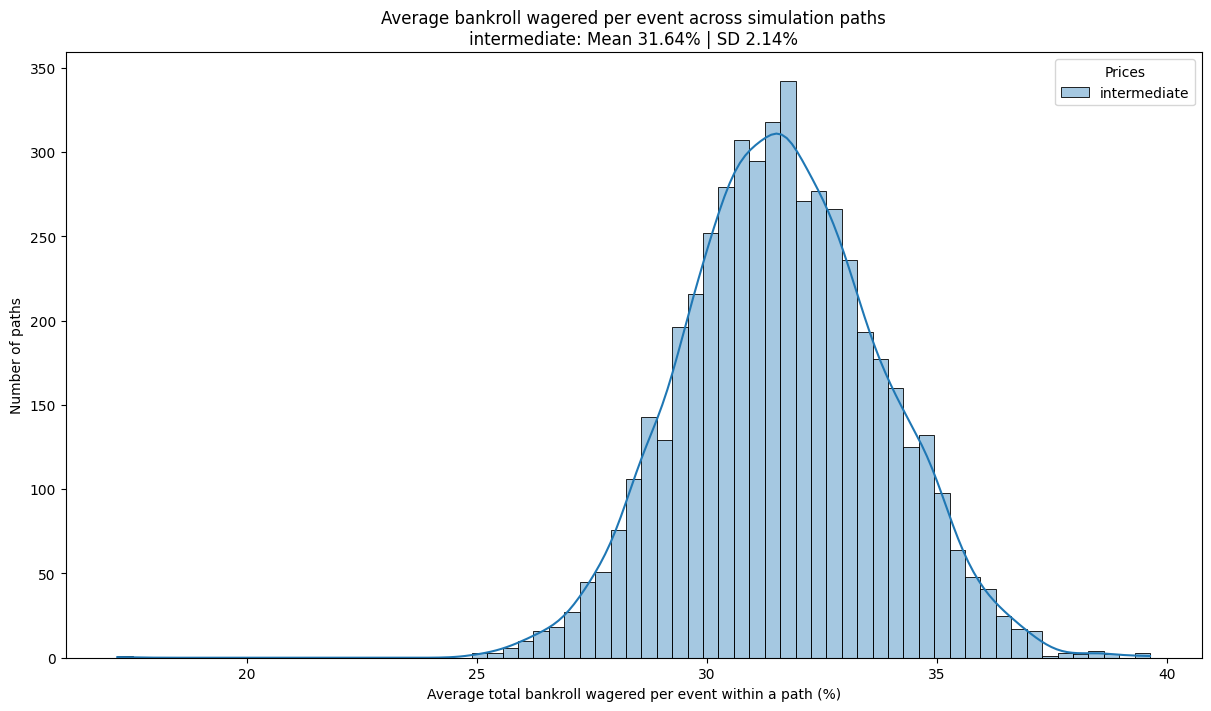

,count,mean,std,min,25%,50%,75%,max
Prices,,,,,,,,
intermediate,5000.0,31.638341,2.139402,17.191414,30.196264,31.594376,33.067409,39.626889


In [9]:
# Each path contributes one final compounded growth rate per event.
growth_by_path = geometric_growth_by_path(results, event_count)
growth_by_path.to_csv(OUTPUT / "geometric_growth_by_path.csv", index=False)
fig, ax = plot_geometric_growth_distribution(growth_by_path)
fig.savefig(OUTPUT / "geometric_growth_distribution.png", dpi=140, bbox_inches="tight")
plt.show()
display(growth_by_path.groupby("Prices")["Geometric growth per event (%)"].describe())
negative_counts = growth_by_path.groupby("Prices")["Negative final bankroll"].sum()
print("Negative final bankroll paths (undefined geometric growth, excluded):", negative_counts.to_dict())
print("Zero final bankroll is included at -100%; no scoring floor or annualization is applied.")

# Average across events within each path; each path contributes one histogram observation.
path_wager_averages, missing_exposure = mean_event_exposure(results)
if missing_exposure:
    print("Wager history unavailable for:", ", ".join(missing_exposure))
    print("Rerun python -m ufc_betting.BettingStrategy.MonteCarlo.run_simulation and reload results to save actual event stake fractions; profits cannot recover stakes.")
if not path_wager_averages.empty:
    path_wager_averages.to_csv(OUTPUT / "mean_bankroll_wagered_by_path.csv", index=False)
    fig, ax = plot_mean_bankroll_wagered(path_wager_averages)
    fig.savefig(OUTPUT / "mean_path_wager_distribution.png", dpi=140, bbox_inches="tight")
    plt.show()
    display(path_wager_averages.groupby("Prices")["Mean bankroll wagered (%)"].describe())


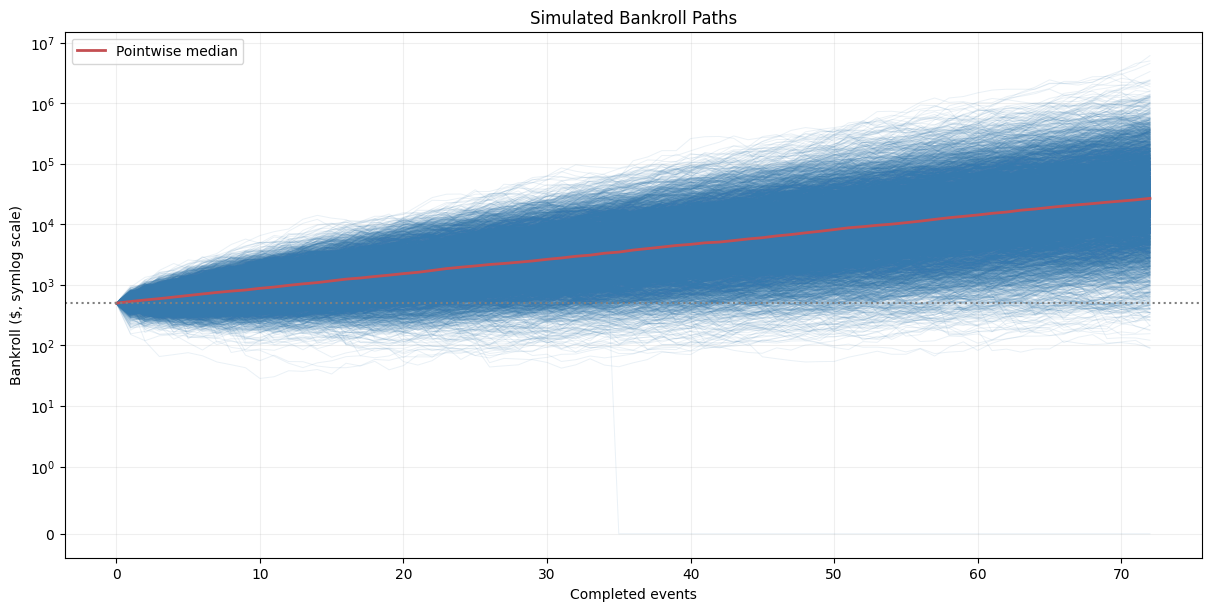

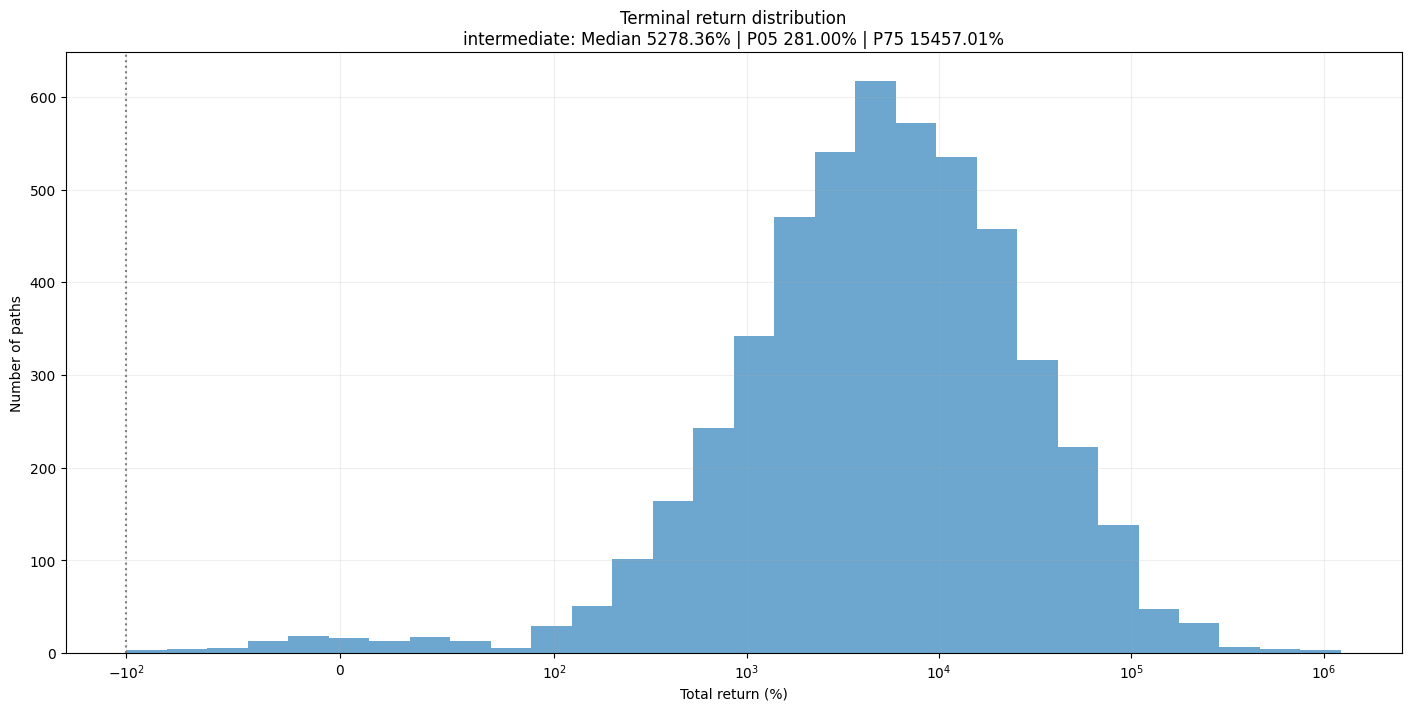

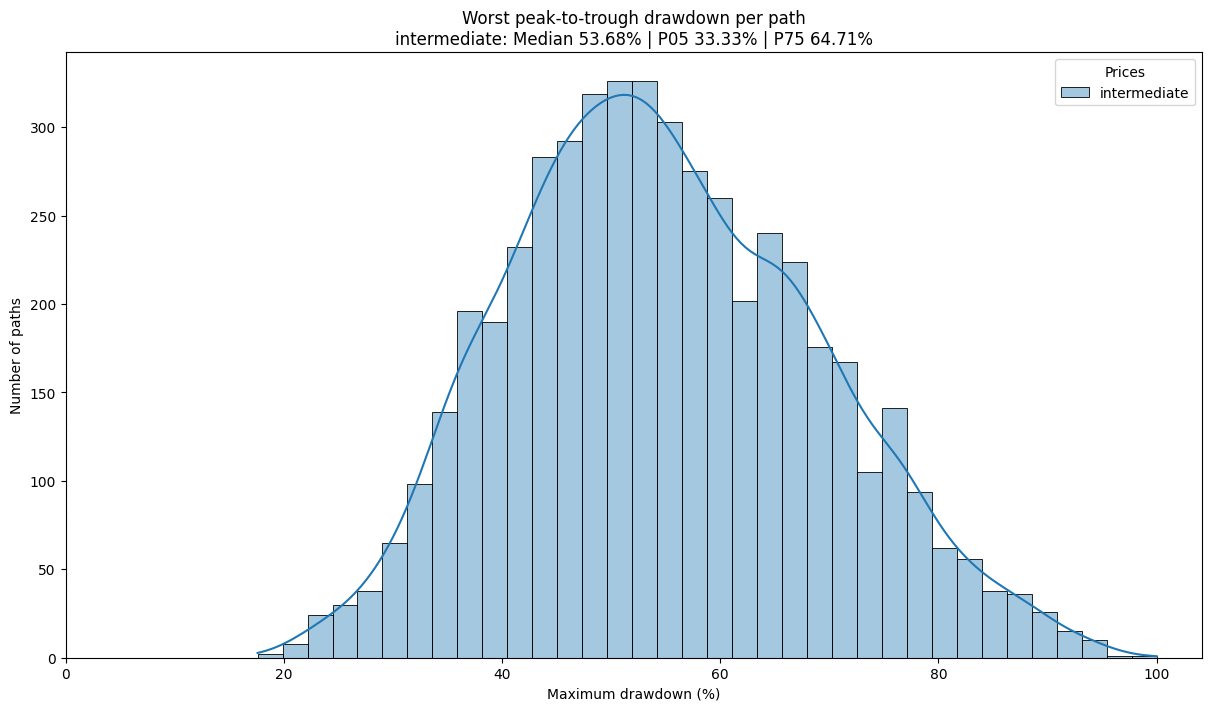

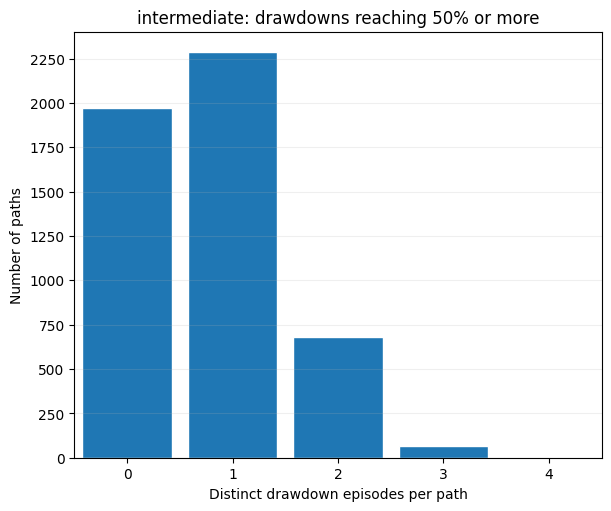

In [10]:
# Plot either fresh simulations or loaded results using the shared helpers.
fig, axes = plot_bankroll_paths(results, len_temp=len_temp, max_paths=max(map(len, target_paths.values())), scale="auto")
fig.savefig(OUTPUT / "bankroll_paths.png", dpi=140, bbox_inches="tight")
plt.show()

fig, axes = plot_terminal_return_distributions(results, cdf_scale="symlog")
fig.savefig(OUTPUT / "terminal_return_distribution.png", dpi=140, bbox_inches="tight")
plt.show()

# Distribution of each path's worst peak-to-trough drawdown.
fig, ax = plot_max_drawdown_histogram(path_statistics)
fig.savefig(OUTPUT / "max_drawdown_histogram.png", dpi=140, bbox_inches="tight")
plt.show()

# Each episode counts once; recovery to the running peak starts a new episode.
fig, axes = plot_drawdown_count_histogram(results)
fig.savefig(OUTPUT / "drawdown_count_histogram.png", dpi=140, bbox_inches="tight")
plt.show()


,Prices,Target ($),Paths,Mean ending bankroll,Mean total return (%),Reached (%),Not reached (%),Mean events (reached only),P05 events (reached only),Median events (reached only),P95 events (reached only)
0,intermediate,5000,5000,81903.88,16280.78,90.02,9.98,38.36,18.0,37.0,65.0
1,intermediate,10000,5000,81903.88,16280.78,79.28,20.72,46.31,25.0,46.0,68.0
2,intermediate,25000,5000,81903.88,16280.78,57.92,42.08,54.14,35.0,55.0,71.0


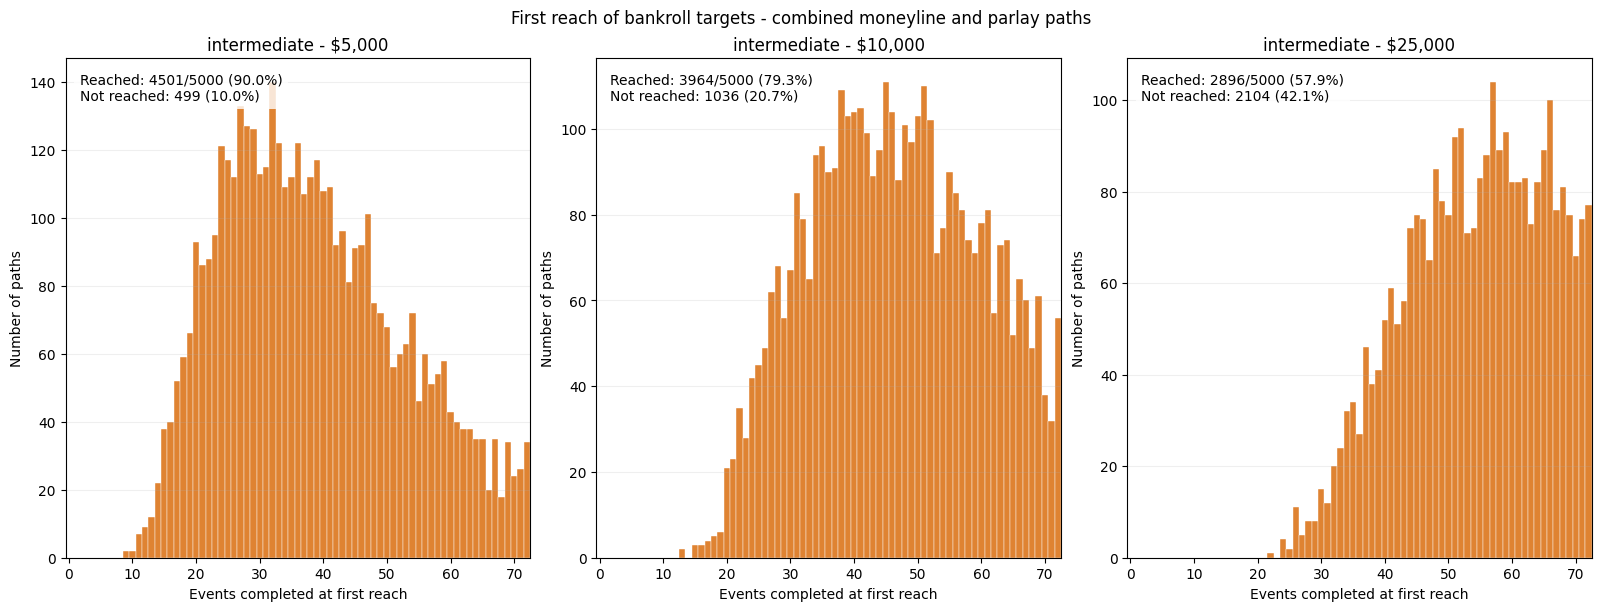

In [11]:
# Target statistics count first crossings; unreached paths remain separate.
target_summary, target_reach_by_path = analyze_bankroll_targets(
    target_paths, targets=TARGETS,
    event_count=event_count, batch_size=len_temp,
)
display(target_summary.round(2))
fig, axes = plot_bankroll_targets(target_reach_by_path, event_count)
fig.savefig(OUTPUT / "events_to_bankroll_targets.png", dpi=140, bbox_inches="tight")
plt.show()
target_summary.to_csv(OUTPUT / "events_to_targets_summary.csv", index=False)
target_reach_by_path.to_csv(OUTPUT / "events_to_targets_by_path.csv", index=False)
